# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  : Ditia Wulandari
- NIM   : 241011401219
- Kelas : Reg B (05TPLM003)

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [1]:
# import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE = 19   # 2 digit terakhir NIM 241011401219

In [ ]:
# train_test_split
def train_test_split(X, y, test_size=0.2, random_state=None):
    rng = np.random.RandomState(random_state)
    n = len(X)
    idx = rng.permutation(n)                 # acak urutan indeks
    n_test = int(round(n * test_size))       # jumlah data testing
    test_idx, train_idx = idx[:n_test], idx[n_test:]
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

In [3]:
# Jawaban A1
df_ads = pd.read_csv("Ads_Data.csv")
print("5 data pertama:")
display(df_ads.head())
print("Jumlah baris data:", len(df_ads))

X = df_ads[["BiayaIklan"]].values      # 2 dimensi (n, 1)
y = df_ads["Penjualan"].values         # 1 dimensi (n,)
print("Shape X:", X.shape, "| Shape y:", y.shape)

plt.figure(figsize=(6, 4))
plt.scatter(X, y, color="tab:blue", edgecolor="k")
plt.title("Biaya Iklan vs Penjualan")
plt.xlabel("Biaya Iklan (juta Rp)")
plt.ylabel("Penjualan (juta Rp)")
plt.grid(alpha=0.3)
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: 'Ads_Data.csv'

### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [ ]:
# Jawaban A2
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("y_train:", y_train.shape, "| y_test:", y_test.shape)

X_train: (32, 1) | X_test: (8, 1)
y_train: (32,) | y_test: (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [ ]:
# Jawaban A3
class LinearRegression:
    """Linear Regression dengan Normal Equation: theta = (X^T X)^-1 X^T y"""
    def fit(self, X, y):
        Xb = np.c_[np.ones(len(X)), X]                       # tambah kolom bias
        theta = np.linalg.pinv(Xb.T @ Xb) @ Xb.T @ y
        self.intercept_, self.coef_ = theta[0], theta[1:]
        return self
    def predict(self, X):
        return self.intercept_ + X @ self.coef_

lin_ne = LinearRegression().fit(X_train, y_train)
b_ne, m_ne = lin_ne.intercept_, lin_ne.coef_[0]
print(f"Intercept (b)  = {b_ne:.4f}")
print(f"Koefisien (m)  = {m_ne:.4f}")
print(f"Persamaan      : y_hat = {b_ne:.4f} + {m_ne:.4f} * BiayaIklan")

Intercept (b)  = 27.7178
Koefisien (m)  = 9.1255
Persamaan      : y_hat = 27.7178 + 9.1255 * BiayaIklan


**Jawaban A3 (interpretasi):**

Persamaan regresi yang diperoleh: $\hat{y} = 27{,}72 + 9{,}13X$.

Koefisien $m = 9{,}13$ berarti **setiap kenaikan biaya iklan 1 juta Rp diikuti kenaikan penjualan rata-rata sekitar 9,13 juta Rp per bulan**, dengan asumsi hubungan linear dan faktor lain tetap. Intercept $b = 27{,}72$ adalah perkiraan penjualan ketika biaya iklan 0, artinya toko tetap punya penjualan dasar sekitar 27,7 juta Rp tanpa iklan. Namun data biaya iklan paling kecil adalah 0,8 juta, sehingga nilai intercept ini sebaiknya dibaca sebagai titik awal garis, bukan prediksi yang pasti.

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [ ]:
# Jawaban A4
def mae(y_true, y_pred):  return np.mean(np.abs(y_true - y_pred))
def mse(y_true, y_pred):  return np.mean((y_true - y_pred) ** 2)
def rmse(y_true, y_pred): return np.sqrt(mse(y_true, y_pred))
def r2_score(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - ss_res / ss_tot

pred_train = lin_ne.predict(X_train)
pred_test  = lin_ne.predict(X_test)

hasil_A4 = pd.DataFrame({
    "MAE":  [mae(y_train, pred_train),  mae(y_test, pred_test)],
    "MSE":  [mse(y_train, pred_train),  mse(y_test, pred_test)],
    "RMSE": [rmse(y_train, pred_train), rmse(y_test, pred_test)],
    "R2":   [r2_score(y_train, pred_train), r2_score(y_test, pred_test)],
}, index=["Training", "Testing"])
display(hasil_A4.round(4))
print("Rentang Penjualan:", y.min(), "-", y.max(), "| Rata-rata:", y.mean().round(2), "| Std:", y.std().round(2))

,MAE,MSE,RMSE,R2
Training,4.9622,41.9134,6.4741,0.9340
Testing,2.9401,13.3969,3.6602,0.9788


Rentang Penjualan: 33.2 - 121.1 | Rata-rata: 74.27 | Std: 25.19


**Jawaban A4 (analisis):**

- **RMSE** training = 6,47 dan testing = 3,66 (juta Rp). Artinya rata-rata tebakan model meleset sekitar 3,7 sampai 6,5 juta Rp dari penjualan sebenarnya. Penjualan berkisar 33,2 sampai 121,1 juta Rp (simpangan baku sekitar 25,2), sehingga kesalahan itu relatif kecil.
- **$R^2$** training = 0,934 dan testing = 0,979. Biaya iklan menjelaskan sekitar 93% sampai 98% variasi penjualan.
- Model ini **sudah baik** untuk data ini dan tidak overfitting, karena performa di data testing sama bagusnya dengan di data training.
- Catatan: nilai testing yang sedikit lebih baik dari training bukan berarti model lebih bagus pada data baru. Data testing hanya 8 titik, dan kebetulan titik-titik itu dekat dengan garis. Beberapa titik yang menyimpang jauh, misalnya biaya 3,4 dengan penjualan 51,7 dan biaya 5,4 dengan penjualan 56,4, berada di data training. Dengan split lain, angka testing bisa lebih rendah.

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

/tmp/ipykernel_303/2067141352.py:12: RuntimeWarning: overflow encountered in square
  self.loss_.append(np.mean(err ** 2))             # catat MSE tiap iterasi
/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:132: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
/tmp/ipykernel_303/2067141352.py:14: RuntimeWarning: overflow encountered in matmul
  self.coef_      -= self.lr * (2 / n) * (X.T @ err)
/tmp/ipykernel_303/2067141352.py:14: RuntimeWarning: invalid value encountered in subtract
  self.coef_      -= self.lr * (2 / n) * (X.T @ err)


,Metode,lr,Intercept,Koefisien,MSE train akhir
0,Normal Equation,-,27.717761,9.125497,41.913365
1,Gradient Descent,0.001,24.492353,9.623045,44.125185
2,Gradient Descent,0.02,27.717761,9.125497,41.913365
3,Gradient Descent,0.1,NaN,NaN,NaN


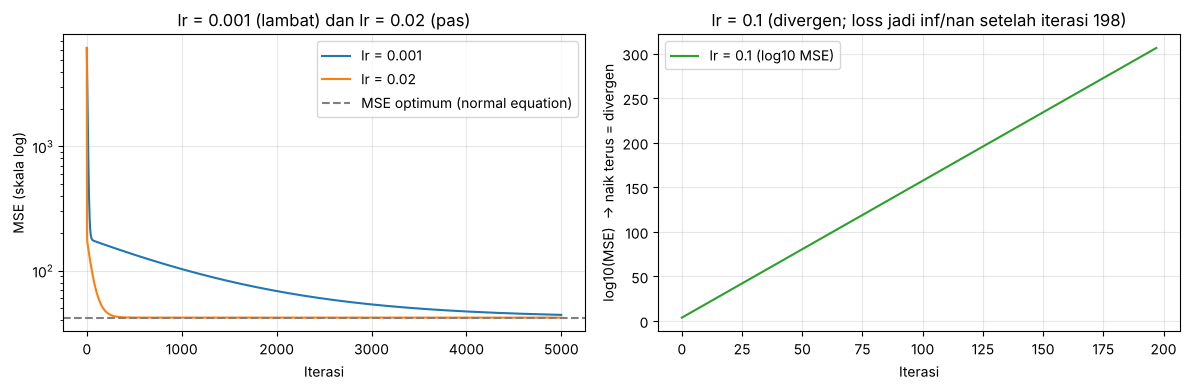

Lambda max Hessian = 68.61 -> lr kritis = 2/lambda_max = 0.0292
Loss lr=0.1 pada iterasi ke 0, 1, 2, 5: [6199.82, 206875.0298858242, 7100423.350149616, 287772761037.277]


In [ ]:
# Jawaban A5
class LinearRegressionGD:
    """Linear Regression dengan Gradient Descent (loss = MSE)"""
    def __init__(self, learning_rate=0.01, n_iterations=1000):
        self.lr, self.n_iter = learning_rate, n_iterations
    def fit(self, X, y):
        n, d = X.shape
        self.intercept_, self.coef_ = 0.0, np.zeros(d)
        self.loss_ = []
        for _ in range(self.n_iter):
            err = self.intercept_ + X @ self.coef_ - y
            self.loss_.append(np.mean(err ** 2))             # catat MSE tiap iterasi
            self.intercept_ -= self.lr * (2 / n) * err.sum()
            self.coef_      -= self.lr * (2 / n) * (X.T @ err)
        return self
    def predict(self, X):
        return self.intercept_ + X @ self.coef_

models_gd = {}
rows = [{"Metode": "Normal Equation", "lr": "-", "Intercept": b_ne, "Koefisien": m_ne, "MSE train akhir": mse(y_train, pred_train)}]
for lr in [0.001, 0.02, 0.1]:
    g = LinearRegressionGD(learning_rate=lr, n_iterations=5000).fit(X_train, y_train)
    models_gd[lr] = g
    rows.append({"Metode": "Gradient Descent", "lr": lr, "Intercept": g.intercept_, "Koefisien": g.coef_[0], "MSE train akhir": g.loss_[-1]})
display(pd.DataFrame(rows))

# Grafik loss vs iterasi (skala log). lr=0.1 dipisah karena nilainya meledak sampai inf/nan
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for lr in [0.001, 0.02]:
    axes[0].plot(models_gd[lr].loss_, label=f"lr = {lr}")
axes[0].axhline(mse(y_train, pred_train), color="gray", ls="--", label="MSE optimum (normal equation)")
axes[0].set_yscale("log")
axes[0].set_title("lr = 0.001 (lambat) dan lr = 0.02 (pas)")
loss_div = np.array(models_gd[0.1].loss_)
ok = np.isfinite(loss_div)
axes[1].plot(np.arange(len(loss_div))[ok], np.log10(loss_div[ok]), color="tab:green", label="lr = 0.1 (log10 MSE)")
axes[1].set_title(f"lr = 0.1 (divergen; loss jadi inf/nan setelah iterasi {ok.sum()})")
for ax in axes:
    ax.set_xlabel("Iterasi"); ax.legend(); ax.grid(alpha=0.3)
axes[0].set_ylabel("MSE (skala log)"); axes[1].set_ylabel("log10(MSE)  -> naik terus = divergen")
plt.tight_layout()
plt.show()

# Batas learning rate agar stabil: lr < 2 / lambda_max(Hessian)
Xb = np.c_[np.ones(len(X_train)), X_train]
H = (2 / len(X_train)) * Xb.T @ Xb
print("Lambda max Hessian =", round(np.linalg.eigvalsh(H).max(), 2), "-> lr kritis = 2/lambda_max =", round(2 / np.linalg.eigvalsh(H).max(), 4))
print("Loss lr=0.1 pada iterasi ke 0, 1, 2, 5:", [float(models_gd[0.1].loss_[i]) for i in (0, 1, 2, 5)])

**Jawaban A5 (analisis):**

- **lr = 0,001 (terlalu lambat).** Setelah 5000 iterasi, intercept = 24,49 dan koefisien = 9,62, sedangkan hasil normal equation 27,72 dan 9,13. MSE akhirnya 44,13, masih di atas MSE optimum 41,91. Langkah tiap iterasi terlalu kecil sehingga belum sampai ke titik minimum. Butuh iterasi lebih banyak.
- **lr = 0,02 (pas).** Intercept dan koefisien identik dengan normal equation sampai belasan angka di belakang koma (27,7178 dan 9,1255), dan MSE akhirnya 41,91. Loss turun cepat lalu mendatar di nilai optimum.
- **lr = 0,1 (divergen).** Hasil akhirnya `nan`. Loss naik terus: 6.199,8 pada iterasi 0, lalu 206.875, lalu 7,1 juta, dan seterusnya sampai di luar jangkauan angka komputer. Penyebabnya, langkah update terlalu besar sehingga parameter melompati titik minimum dan mendarat lebih jauh dari sebelumnya, sehingga galat makin besar di setiap iterasi. Secara teori GD stabil jika $lr < 2/\lambda_{max}$ dari Hessian. Pada data ini batasnya sekitar 0,029, sehingga lr = 0,02 aman dan lr = 0,1 pasti gagal.
- **Arti `RuntimeWarning: overflow`:** nilai loss dan parameter yang terus membesar melebihi batas angka yang bisa disimpan (float64), lalu menjadi `inf` dan akhirnya `nan`. Ini tanda GD tidak konvergen karena learning rate terlalu besar, bukan karena ada bug.

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

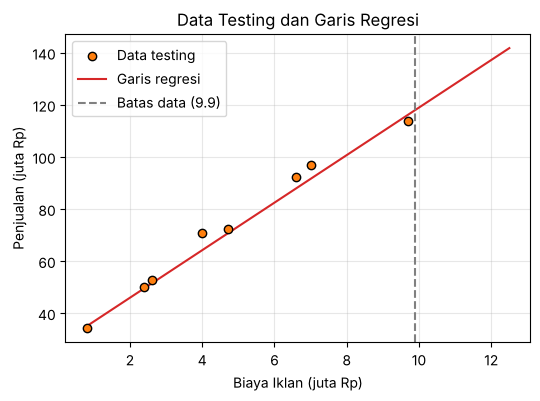

,BiayaIklan (juta),Prediksi Penjualan (juta)
0,4.5,68.78
1,7.0,91.60
2,12.0,137.22


Rentang BiayaIklan pada data: 0.8 - 9.9


In [ ]:
# Jawaban A6
x_line = np.linspace(X.min(), 12.5, 100).reshape(-1, 1)
plt.figure(figsize=(6, 4))
plt.scatter(X_test, y_test, color="tab:orange", edgecolor="k", label="Data testing", zorder=3)
plt.plot(x_line, lin_ne.predict(x_line), color="tab:red", label="Garis regresi")
plt.axvline(X.max(), color="gray", ls="--", label="Batas data (9.9)")
plt.title("Data Testing dan Garis Regresi")
plt.xlabel("Biaya Iklan (juta Rp)"); plt.ylabel("Penjualan (juta Rp)")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

biaya_baru = np.array([[4.5], [7.0], [12.0]])
prediksi = lin_ne.predict(biaya_baru)
display(pd.DataFrame({"BiayaIklan (juta)": biaya_baru.ravel(), "Prediksi Penjualan (juta)": prediksi.round(2)}))
print("Rentang BiayaIklan pada data:", X.min(), "-", X.max())

**Jawaban A6 (analisis):**

Prediksi penjualan: biaya iklan 4,5 juta menghasilkan sekitar **68,78 juta**, 7 juta menghasilkan sekitar **91,60 juta**, dan 12 juta menghasilkan sekitar **137,22 juta**.

Prediksi untuk 12 juta adalah ekstrapolasi karena biaya iklan terbesar di data hanya 9,9 juta. Hasil ini **kurang bisa dipercaya**. Model hanya dilatih pada rentang 0,8 sampai 9,9 juta, jadi tidak ada bukti bahwa hubungannya tetap linear di luar rentang itu. Dalam kenyataan, kenaikan penjualan biasanya melambat (*diminishing returns*) karena pasar mulai jenuh, sehingga garis lurus cenderung menaksir terlalu tinggi. Prediksi 4,5 juta dan 7 juta berada di dalam rentang data (interpolasi) sehingga jauh lebih aman.

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

5 data pertama:


,JumlahLink,KataPromo,Spam
0,0,0,0
1,2,4,0
2,6,7,1
3,10,8,1
4,8,7,1


Jumlah baris data: 60

Jumlah per kelas:
Bukan Spam (0): 35
Spam (1)      : 25
Shape X2: (60, 2) | Shape y2: (60,)


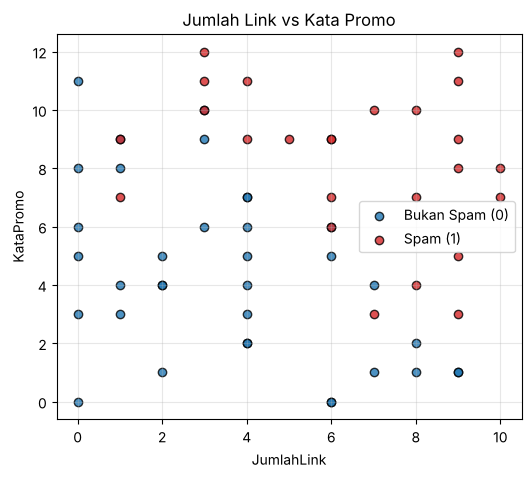

In [ ]:
# Jawaban B1
df_email = pd.read_csv("Email_Data.csv")
print("5 data pertama:")
display(df_email.head())
print("Jumlah baris data:", len(df_email))
print("\nJumlah per kelas:")
print("Bukan Spam (0):", (df_email["Spam"] == 0).sum())
print("Spam (1)      :", (df_email["Spam"] == 1).sum())

X2 = df_email[["JumlahLink", "KataPromo"]].values
y2 = df_email["Spam"].values
print("Shape X2:", X2.shape, "| Shape y2:", y2.shape)

plt.figure(figsize=(6, 5))
plt.scatter(X2[y2 == 0, 0], X2[y2 == 0, 1], c="tab:blue", edgecolor="k", label="Bukan Spam (0)", alpha=0.8)
plt.scatter(X2[y2 == 1, 0], X2[y2 == 1, 1], c="tab:red", edgecolor="k", label="Spam (1)", alpha=0.8)
plt.title("Jumlah Link vs Kata Promo")
plt.xlabel("JumlahLink"); plt.ylabel("KataPromo")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

Train: (45, 2) | Test: (15, 2)
Kelas di data testing -> Bukan Spam: 10 | Spam: 5



Intercept (b) = -8.4097
m1 (JumlahLink) = 0.7272
m2 (KataPromo)  = 0.7292
P(Spam) = sigmoid(-8.4097 + 0.7272*JumlahLink + 0.7292*KataPromo)
Log loss awal: 0.6931 | iterasi 1000: 0.355 | iterasi 5000: 0.3245 | akhir: 0.3236


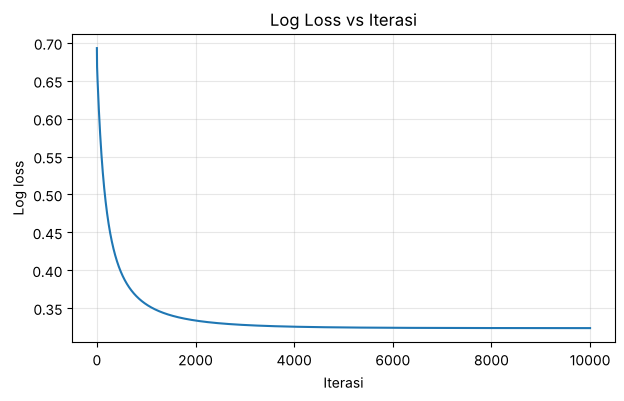

In [ ]:
# Jawaban B2
def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

class LogisticRegression:
    """Logistic Regression dengan Gradient Descent (loss = log loss)"""
    def __init__(self, learning_rate=0.1, n_iterations=1000):
        self.lr, self.n_iter = learning_rate, n_iterations
    def fit(self, X, y):
        n, d = X.shape
        self.intercept_, self.coef_ = 0.0, np.zeros(d)
        self.loss_ = []
        eps = 1e-12                                          # hindari log(0)
        for _ in range(self.n_iter):
            p = sigmoid(self.intercept_ + X @ self.coef_)
            self.loss_.append(-np.mean(y * np.log(p + eps) + (1 - y) * np.log(1 - p + eps)))
            err = p - y
            self.intercept_ -= self.lr * err.mean()
            self.coef_      -= self.lr * (X.T @ err) / n
        return self
    def predict_proba(self, X):
        return sigmoid(self.intercept_ + X @ self.coef_)
    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y2, test_size=0.25, random_state=RANDOM_STATE)
print("Train:", X2_train.shape, "| Test:", X2_test.shape)
print("Kelas di data testing -> Bukan Spam:", (y2_test == 0).sum(), "| Spam:", (y2_test == 1).sum())

clf = LogisticRegression(learning_rate=0.1, n_iterations=10000).fit(X2_train, y2_train)
b0, (m1, m2) = clf.intercept_, clf.coef_
print(f"\nIntercept (b) = {b0:.4f}")
print(f"m1 (JumlahLink) = {m1:.4f}")
print(f"m2 (KataPromo)  = {m2:.4f}")
print(f"P(Spam) = sigmoid({b0:.4f} + {m1:.4f}*JumlahLink + {m2:.4f}*KataPromo)")
print("Log loss awal:", round(clf.loss_[0], 4), "| iterasi 1000:", round(clf.loss_[999], 4),
      "| iterasi 5000:", round(clf.loss_[4999], 4), "| akhir:", round(clf.loss_[-1], 4))

plt.figure(figsize=(7, 4))
plt.plot(clf.loss_)
plt.title("Log Loss vs Iterasi")
plt.xlabel("Iterasi"); plt.ylabel("Log loss")
plt.grid(alpha=0.3)
plt.show()

**Jawaban B2 (analisis):**

Persamaan model: $P(\text{Spam}) = \sigma(-8{,}41 + 0{,}727 \cdot \text{JumlahLink} + 0{,}729 \cdot \text{KataPromo})$.

Kedua koefisien positif, jadi makin banyak link dan kata promosi, makin besar peluang email dianggap spam. Setiap tambahan satu link atau satu kata promosi menaikkan odds spam sekitar 2,07 kali ($e^{0{,}727} \approx e^{0{,}729} \approx 2{,}07$). Kedua fitur berpengaruh hampir sama kuat.

**Loss sudah turun dan stabil.** Log loss turun dari 0,693 (tebakan acak, $\ln 2$) menjadi 0,355 pada iterasi 1000, 0,3245 pada iterasi 5000, dan 0,3236 di akhir. Dari iterasi 5000 sampai 10000 loss hanya turun sekitar 0,001, sehingga bisa dianggap sudah konvergen.

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [ ]:
# Jawaban B3
def accuracy_score(y_true, y_pred):
    return np.mean(y_true == y_pred)

def confusion_matrix(y_true, y_pred):
    tn = np.sum((y_true == 0) & (y_pred == 0)); fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0)); tp = np.sum((y_true == 1) & (y_pred == 1))
    return np.array([[tn, fp], [fn, tp]])        # baris = aktual, kolom = prediksi

def precision_score(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1)); fp = np.sum((y_true == 0) & (y_pred == 1))
    return tp / (tp + fp) if (tp + fp) > 0 else 0.0

def recall_score(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1)); fn = np.sum((y_true == 1) & (y_pred == 0))
    return tp / (tp + fn) if (tp + fn) > 0 else 0.0

def f1_score(y_true, y_pred):
    p, r = precision_score(y_true, y_pred), recall_score(y_true, y_pred)
    return 2 * p * r / (p + r) if (p + r) > 0 else 0.0

pred2_test  = clf.predict(X2_test)
pred2_train = clf.predict(X2_train)
print("Evaluasi pada DATA TESTING")
print("Accuracy :", round(accuracy_score(y2_test, pred2_test), 4))
print("Precision:", round(precision_score(y2_test, pred2_test), 4))
print("Recall   :", round(recall_score(y2_test, pred2_test), 4))
print("F1-score :", round(f1_score(y2_test, pred2_test), 4))
print("Confusion matrix [[TN, FP], [FN, TP]]:")
print(confusion_matrix(y2_test, pred2_test))
print("\nPembanding -> Accuracy pada data training:", round(accuracy_score(y2_train, pred2_train), 4))

Evaluasi pada DATA TESTING
Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1-score : 1.0
Confusion matrix [[TN, FP], [FN, TP]]:
[[10  0]
 [ 0  5]]

Pembanding -> Accuracy pada data training: 0.8667


**Jawaban B3 (analisis):**

Pada data testing (15 email): accuracy = 1,0, precision = 1,0, recall = 1,0, F1 = 1,0. Confusion matrix-nya `[[10, 0], [0, 5]]`, yaitu 10 email bukan spam dan 5 email spam semuanya terklasifikasi benar. Sebagai pembanding, accuracy pada data training "hanya" 0,867. Hasil sempurna di testing ini perlu dibaca hati-hati: datanya cuma 15 email, jadi kebetulan split ini mudah. Performa sebenarnya lebih mendekati angka training.

- **FP (false positive):** email asli (bukan spam) yang salah diprediksi spam, sehingga masuk folder spam.
- **FN (false negative):** email spam yang lolos dan salah diprediksi bukan spam, sehingga masuk inbox.

Menurut saya **FP lebih merugikan**. Email penting seperti info kerja, tagihan, atau undangan wawancara bisa tidak terbaca dan akibatnya sulit diperbaiki. FN hanya membuat pengguna melihat satu email spam yang mengganggu dan bisa langsung dihapus.

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

Decision boundary: x2 = -(-8.4097 + 0.7272 * x1) / 0.7292
                   x2 = 11.5324 - 0.9972 * x1


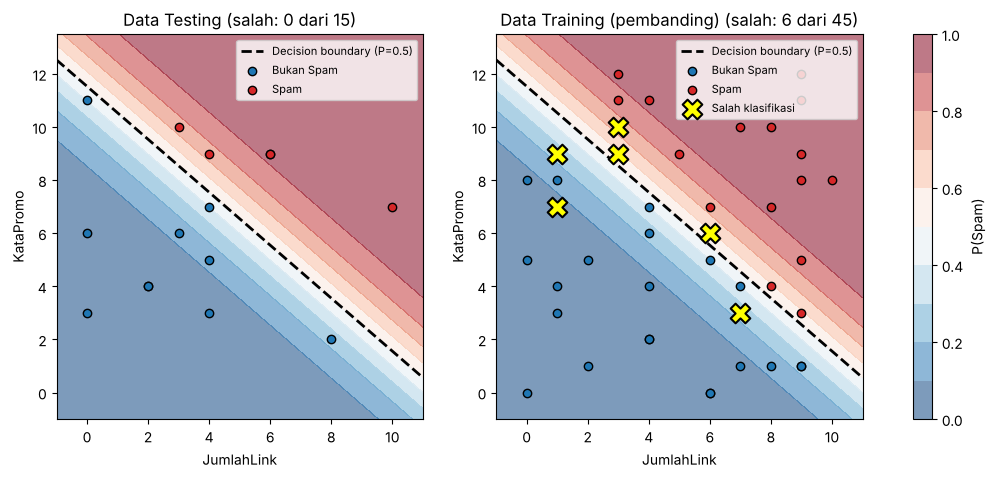

Data testing yang salah diklasifikasikan: 0
Data training yang salah diklasifikasikan: 6


,JumlahLink,KataPromo,Aktual,Prediksi,P(Spam)
0,1,7,1,0,0.071
1,1,9,1,0,0.246
2,6,6,0,1,0.581
3,3,9,0,1,0.583
4,7,3,1,0,0.244
5,3,10,0,1,0.743


In [ ]:
# Jawaban B4
# Decision boundary: b + m1*x1 + m2*x2 = 0  ->  x2 = -(b + m1*x1)/m2
print(f"Decision boundary: x2 = -({b0:.4f} + {m1:.4f} * x1) / {m2:.4f}")
print(f"                   x2 = {-b0/m2:.4f} - {m1/m2:.4f} * x1")

def plot_boundary(ax, Xd, yd, pred, judul):
    xx, yy = np.meshgrid(np.linspace(-1, 11, 300), np.linspace(-1, 13.5, 300))
    zz = clf.predict_proba(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    cf = ax.contourf(xx, yy, zz, levels=np.linspace(0, 1, 11), cmap="RdBu_r", alpha=0.55)
    x1 = np.linspace(-1, 11, 100)
    ax.plot(x1, -(b0 + m1 * x1) / m2, "k--", lw=2, label="Decision boundary (P=0.5)")
    ax.scatter(Xd[yd == 0, 0], Xd[yd == 0, 1], c="tab:blue", edgecolor="k", label="Bukan Spam")
    ax.scatter(Xd[yd == 1, 0], Xd[yd == 1, 1], c="tab:red", edgecolor="k", label="Spam")
    salah = pred != yd
    if salah.any():
        ax.scatter(Xd[salah, 0], Xd[salah, 1], marker="X", s=200, c="yellow", edgecolor="k", linewidths=1.5, label="Salah klasifikasi", zorder=5)
    ax.set_xlim(-1, 11); ax.set_ylim(-1, 13.5)
    ax.set_title(f"{judul} (salah: {salah.sum()} dari {len(yd)})")
    ax.set_xlabel("JumlahLink"); ax.set_ylabel("KataPromo"); ax.legend(loc="upper right", fontsize=8)
    return cf

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
cf = plot_boundary(axes[0], X2_test, y2_test, pred2_test, "Data Testing")
plot_boundary(axes[1], X2_train, y2_train, pred2_train, "Data Training (pembanding)")
fig.colorbar(cf, ax=axes, label="P(Spam)")
plt.show()

salah_test = np.where(pred2_test != y2_test)[0]
print("Data testing yang salah diklasifikasikan:", len(salah_test))
salah_train = np.where(pred2_train != y2_train)[0]
print("Data training yang salah diklasifikasikan:", len(salah_train))
display(pd.DataFrame({"JumlahLink": X2_train[salah_train, 0], "KataPromo": X2_train[salah_train, 1],
                      "Aktual": y2_train[salah_train], "Prediksi": pred2_train[salah_train],
                      "P(Spam)": clf.predict_proba(X2_train[salah_train]).round(3)}))

**Jawaban B4 (analisis):**

Decision boundary: $x_2 = -\frac{-8{,}41 + 0{,}727x_1}{0{,}729} \approx 11{,}53 - 0{,}997x_1$. Garis ini hampir sama dengan $x_1 + x_2 \approx 11{,}5$. Email dengan jumlah link ditambah kata promosi di atas sekitar 11,5 diprediksi spam, dan di bawahnya bukan spam. Batas ini linear, dan karena kedua koefisien hampir sama, kedua fitur dianggap sama penting.

**Pada data testing tidak ada email yang salah diklasifikasikan** (0 dari 15). Semua titik biru berada di sisi bawah garis dan semua titik merah di sisi atas, sehingga tidak ada penanda salah klasifikasi (X kuning) di panel kiri. Pada data training (panel kanan) ada 6 titik yang salah, yaitu spam dengan sedikit link atau kata promosi (misalnya 1 link dan 7 kata promo) dan email biasa dengan kata promosi banyak (misalnya 3 link dan 10 kata promo). Tabel di bawah grafik menunjukkan daftarnya. Kesalahan itu terjadi karena data Spam dan Bukan Spam saling tumpang tindih di sekitar batas, sehingga tidak ada garis lurus yang bisa memisahkannya dengan sempurna.

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [ ]:
# Jawaban B5
proba_test  = clf.predict_proba(X2_test)
proba_train = clf.predict_proba(X2_train)

def tabel_threshold(proba, yd):
    rows = []
    for t in [0.3, 0.5, 0.7]:
        pred = (proba >= t).astype(int)
        cm = confusion_matrix(yd, pred)
        rows.append({"Threshold": t, "TN": cm[0, 0], "FP": cm[0, 1], "FN": cm[1, 0], "TP": cm[1, 1],
                     "Precision": round(precision_score(yd, pred), 4), "Recall": round(recall_score(yd, pred), 4),
                     "Accuracy": round(accuracy_score(yd, pred), 4)})
    return pd.DataFrame(rows)

print("DATA TESTING (15 email)")
display(tabel_threshold(proba_test, y2_test))
print("DATA TRAINING (45 email) - sebagai bukti tambahan karena data testing sangat kecil")
display(tabel_threshold(proba_train, y2_train))

DATA TESTING (15 email)


,Threshold,TN,FP,FN,TP,Precision,Recall,Accuracy
0,0.3,8,2,0,5,0.7143,1.0,0.8667
1,0.5,10,0,0,5,1.0000,1.0,1.0000
2,0.7,10,0,0,5,1.0000,1.0,1.0000


DATA TRAINING (45 email) - sebagai bukti tambahan karena data testing sangat kecil


,Threshold,TN,FP,FN,TP,Precision,Recall,Accuracy
0,0.3,19,6,3,17,0.7391,0.85,0.8000
1,0.5,22,3,3,17,0.8500,0.85,0.8667
2,0.7,24,1,6,14,0.9333,0.70,0.8444


**Jawaban B5 (analisis):**

**Pengaruh threshold.** Menaikkan threshold membuat model lebih "pelit" melabeli spam: FP berkurang sehingga **precision naik**, tetapi spam yang ragu-ragu ikut lolos sehingga FN bertambah dan **recall turun**. Menurunkan threshold berefek sebaliknya.

**Bukti pada data.** Pada data testing, threshold 0,3 menghasilkan 2 FP (precision turun ke 0,714, recall tetap 1,0), sedangkan threshold 0,5 dan 0,7 sama-sama sempurna. Karena data testing hanya 15 email, saya cek juga data training (45 email). Di sana efek naik-turun terlihat jelas: threshold 0,3 memberi precision 0,739 dan recall 0,85; threshold 0,5 memberi precision 0,85 dan recall 0,85; threshold 0,7 memberi precision 0,933 tetapi recall turun ke 0,70.

**Threshold yang saya pilih: 0,7.** Berdasarkan B3, FP (email penting masuk folder spam) lebih merugikan daripada FN, jadi precision perlu diutamakan. Threshold 0,7 menekan FP paling kecil (1 pada data training, 0 pada data testing). Kekurangannya, sekitar 30% spam di data training lolos ke inbox. Kalau pengguna tidak tahan dengan spam yang lolos sebanyak itu, 0,5 adalah kompromi yang seimbang.

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [ ]:
# Jawaban B6
THRESHOLD = 0.7     # threshold pilihan dari Soal B5
email_baru = np.array([[1, 2], [5, 6], [9, 10], [2, 11]])
proba_baru = clf.predict_proba(email_baru)
hasil_B6 = pd.DataFrame({
    "Email": ["E1", "E2", "E3", "E4"],
    "JumlahLink": email_baru[:, 0],
    "KataPromo": email_baru[:, 1],
    "P(Spam)": proba_baru.round(4),
    "Prediksi": np.where(proba_baru >= THRESHOLD, "Spam", "Bukan Spam"),
})
display(hasil_B6)

,Email,JumlahLink,KataPromo,P(Spam),Prediksi
0,E1,1,2,0.0020,Bukan Spam
1,E2,5,6,0.4017,Bukan Spam
2,E3,9,10,0.9956,Spam
3,E4,2,11,0.7439,Spam


**Jawaban B6 (analisis):**

Dengan threshold 0,7: **E1** (1 link, 2 kata promo) P(Spam) = 0,002, **bukan spam**. **E2** (5 link, 6 kata promo) P = 0,402, **bukan spam**, tetapi sudah di wilayah ragu-ragu karena berada dekat decision boundary. **E3** (9 link, 10 kata promo) P = 0,996, **spam**. **E4** (2 link, 11 kata promo) P = 0,744, **spam**, namun hanya sedikit di atas threshold 0,7. Hasil untuk keempat email ini sama persis jika dipakai threshold 0,5.

---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:** Logistic Regression termasuk klasifikasi karena outputnya adalah peluang sebuah data masuk ke kelas tertentu, yang kemudian diubah menjadi label kelas lewat threshold (misalnya 0,5), bukan angka kontinu. Kata "regression" hanya berasal dari proses di dalamnya, yaitu menghitung kombinasi linear $z = b + m_1x_1 + m_2x_2$. Fungsi **sigmoid** $\sigma(z) = 1/(1+e^{-z})$ mengubah $z$ yang bisa bernilai berapa saja menjadi angka antara 0 dan 1 sehingga bisa dibaca sebagai probabilitas. Tanpa sigmoid, output regresi linear bisa negatif atau lebih dari 1 dan tidak bisa ditafsirkan sebagai peluang.

**Jawaban C2:** Normal equation menghitung parameter langsung dalam satu kali hitung dengan rumus $\theta = (X^TX)^{-1}X^Ty$, hasilnya eksak dan tanpa learning rate. Gradient descent mencarinya secara bertahap: parameter diperbarui berulang kali ke arah yang menurunkan loss, dan hasilnya bergantung pada learning rate dan jumlah iterasi (seperti terlihat pada Soal A5). Gradient descent sebaiknya dipakai ketika data sangat besar atau fiturnya sangat banyak, karena menghitung invers $X^TX$ sangat mahal (sekitar $O(d^3)$) dan bisa tidak stabil. Gradient descent juga dipakai untuk model yang tidak punya rumus langsung, misalnya Logistic Regression.

**Jawaban C3:** Model harus dievaluasi pada data testing karena data itu belum pernah dilihat saat training, sehingga hasilnya menggambarkan kemampuan model pada data baru. Jika dievaluasi pada data training, model yang sekadar menghafal data akan tampak bagus. **Overfitting** adalah kondisi ketika model terlalu menyesuaikan diri dengan data training, termasuk noise-nya, sehingga skornya tinggi di data training tetapi jauh lebih rendah di data testing. Pada tugas ini tidak terjadi overfitting karena skor testing sama baiknya dengan training.

**Jawaban C4:** Linear Regression menghasilkan nilai kontinu, sehingga ukuran kesalahan yang wajar adalah jarak kuadrat antara prediksi dan nilai aktual (MSE). MSE juga mudah diturunkan dan fungsinya cembung pada model linear. Logistic Regression menghasilkan probabilitas antara 0 dan 1 untuk label 0 atau 1, sehingga ukuran yang tepat adalah log loss yang memberi hukuman sangat besar jika model yakin tetapi salah (misalnya prediksi 0,99 padahal kelas sebenarnya 0). Jika MSE dipakai pada sigmoid, fungsi loss-nya tidak lagi cembung dan gradiennya mengecil saat prediksi salah jauh, sehingga training menjadi lambat atau macet.

**Jawaban C5:** Karena `random_state` kita berbeda (dua digit terakhir NIM), pembagian data training dan testing berbeda. Model dilatih pada data yang berbeda, sehingga koefisien, loss, dan akurasi ikut berbeda, terutama karena datasetnya kecil dan tiap titik berpengaruh besar. Itu normal dan justru menunjukkan bahwa hasil evaluasi bergantung pada pembagian data. Algoritma dan datanya sama, tetapi sampel yang dilihat model dan yang dipakai untuk menguji berbeda.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [ ]:
# Jawaban Bonus
from sklearn.linear_model import LinearRegression as SkLinear, LogisticRegression as SkLogistic

# --- Linear Regression ---
sk_lin = SkLinear().fit(X_train, y_train)
print("LINEAR REGRESSION")
print(f"Buatan sendiri: intercept = {lin_ne.intercept_:.6f}, koef = {lin_ne.coef_[0]:.6f}, R2 test = {r2_score(y_test, lin_ne.predict(X_test)):.6f}")
print(f"scikit-learn  : intercept = {sk_lin.intercept_:.6f}, koef = {sk_lin.coef_[0]:.6f}, R2 test = {r2_score(y_test, sk_lin.predict(X_test)):.6f}")

# --- Logistic Regression ---
sk_log_default = SkLogistic(max_iter=10000).fit(X2_train, y2_train)                  # default: penalty L2, C=1.0
sk_log_nopen   = SkLogistic(C=np.inf, max_iter=10000).fit(X2_train, y2_train)    # C sangat besar = tanpa regularisasi (setara penalty=None)
rows = [("Buatan sendiri", clf.intercept_, clf.coef_[0], clf.coef_[1], accuracy_score(y2_test, clf.predict(X2_test)))]
for nama, mdl in [("sklearn default (L2, C=1)", sk_log_default), ("sklearn tanpa regularisasi (C=inf)", sk_log_nopen)]:
    rows.append((nama, mdl.intercept_[0], mdl.coef_[0][0], mdl.coef_[0][1], accuracy_score(y2_test, mdl.predict(X2_test))))
print("\nLOGISTIC REGRESSION")
display(pd.DataFrame(rows, columns=["Model", "Intercept", "m1 (JumlahLink)", "m2 (KataPromo)", "Accuracy test"]).round(4))

LINEAR REGRESSION
Buatan sendiri: intercept = 27.717761, koef = 9.125497, R2 test = 0.978774
scikit-learn  : intercept = 27.717761, koef = 9.125497, R2 test = 0.978774

LOGISTIC REGRESSION


,Model,Intercept,m1 (JumlahLink),m2 (KataPromo),Accuracy test
0,Buatan sendiri,-8.4097,0.7272,0.7292,1.0
1,"sklearn default (L2, C=1)",-7.8110,0.6702,0.6790,1.0
2,sklearn tanpa regularisasi (C=inf),-8.5603,0.7409,0.7415,1.0


**Jawaban Bonus (analisis):**

- **Linear Regression:** hasil scikit-learn **identik** dengan implementasi saya (intercept 27,7178 dan koefisien 9,1255). Keduanya menyelesaikan masalah kuadrat terkecil yang sama dan solusinya tunggal.
- **Logistic Regression:** koefisien scikit-learn default (intercept −7,81; $m_1$ = 0,670; $m_2$ = 0,679) **berbeda** dari milik saya (−8,41; 0,727; 0,729). Penyebabnya, `LogisticRegression` scikit-learn memakai **regularisasi L2** secara default (`penalty="l2"`, `C=1.0`). Regularisasi menambahkan hukuman pada besarnya koefisien sehingga koefisien "ditarik" mengecil. Implementasi saya tidak memakai regularisasi.
- Saat regularisasi dimatikan (`C=np.inf`, setara `penalty=None`), koefisien scikit-learn naik menjadi 0,741 dan 0,741 (intercept −8,56). Itu jauh lebih dekat ke hasil saya. Selisih yang tersisa wajar karena implementasi saya memakai gradient descent dengan jumlah iterasi terbatas, sementara scikit-learn memakai optimizer lain (L-BFGS) sampai konvergen penuh, dan loss di data ini masih menurun sangat pelan pada iterasi terakhir.
- Dari sisi evaluasi, ketiga model sama-sama mencapai accuracy 1,0 pada data testing, sehingga perbedaan koefisien tidak mengubah prediksi pada data testing ini.